# 02 · Training a Behavior Cloning Policy
**Time: 50–60 minutes, including discussion and both real training/evaluation runs.**

## Learning Objectives
Explain behavior cloning (BC), interpret training and validation loss, and conduct a controlled learning-rate experiment.

## Background
BC predicts the expert action from the current observation. The optimizer updates network weights to reduce mean squared action error (MSE). Validation uses unseen episodes to select a checkpoint (saved model weights); test rollouts never update the model or select the primary variant. A small action error on recorded states does not guarantee successful closed-loop behavior.

## Step-by-step Instructions
### Step 1 — Inspect the frozen experiment
Keep the dataset, episode split, architecture (three 256-unit hidden layers), initialization seed 17, batch size and 50-epoch budget fixed. Compare learning rates **0.001 and 0.0003**. This is mandatory. Both variants start with identical weights. `lr_a` is the primary model, chosen before seeing test results.


> **Executed instructor solution — 2026-10-13.** Original student templates are preserved. Computation and answer-edit sessions are recorded in solution_execution.json. These answers interpret this particular run. Training and policy evaluation were each performed once in the completed run.

In [1]:
from pathlib import Path
import os, json
from IPython.display import display, Markdown, Image, Video
from manipulation_lab.common import ROOT, DATA, write_json
from manipulation_lab.notebook import workspace, command, next_stage, stage_path
from manipulation_lab.teaching import read_json, markdown_table
GROUP = os.environ.get("LAB_GROUP", "group_01")  # Use the group assigned by your instructor.
RUN = workspace(GROUP)
settings = read_json(ROOT / "configs/bc_student.json")
settings["device"] = os.environ.get("LAB_DEVICE", settings["device"])
design = read_json(ROOT / "configs/controlled_experiment.json")
display(Markdown(markdown_table([settings])))
print("Controlled experiment:", design)


group_01 → /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c


| name | architecture | hidden_dims | learning_rate | epochs | batch_size | seed | device | normalize_obs | sequence_length | cpu_threads | timeout_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| student_deterministic_mlp | mlp | [256, 256, 256] | 0.001 | 50 | 256 | 17 | cpu | True | 1 | 2 | 3600 |

Controlled experiment: {'learning_rates': [0.001, 0.0003], 'primary_variant': 'lr_a', 'selection_rule': 'Primary variant fixed before evaluation; do not select using test success'}


### Step 2 — Inspect the existing model and expert labels
The code below shows the unchanged robomimic model. Its training step predicts actions, computes MSE against expert actions, differentiates that loss, and updates weights. An epoch is one complete pass over the training examples.


In [2]:
import h5py, torch
from manipulation_lab.policy import make_config, make_model
from manipulation_lab.dataset import inspect
info = inspect(DATA)
example_model = make_model(make_config(settings), info["policy_observation_shapes"], torch.device("cpu"))
print(example_model.nets["policy"])
with h5py.File(DATA, "r") as f:
    episode = info["splits"]["train"][0]
    print("First three expert action labels:", f[f"data/{episode}/actions"][:3])
del example_model


ROBOMIMIC WARNING(
    No private macro file found!
    It is recommended to use a private macro file
    To setup, run: python /home/jingchen/projects/manipulation_lab/third_party/robomimic/robomimic/scripts/setup_macros.py
)


/home/jingchen/projects/manipulation_lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_eef_pos', 'object', 'robot0_eef_quat', 'robot0_gripper_qpos']
using obs modality: rgb with keys: []
using obs modality: depth with keys: []
using obs modality: scan with keys: []
ObservationKeyToModalityDict: action not found, adding action to mapping with assumed low_dim modality!
ActorNetwork(
    action_dim=7

    encoder=ObservationGroupEncoder(
        group=obs
        ObservationEncoder(
            Key(
                name=robot0_eef_pos
                shape=[3]
                modality=low_dim
                randomizer=None
                net=None
                sharing_from=None
            )
            Key(
                name=robot0_eef_quat
                shape=[4]
                modality=low_dim
                randomizer=None
                net=None
                sharing_from=None
            )
            Key(
                name=robot0_

### Step 3 — Run both configurations
The next cell performs **two actual training jobs**, reloads both selected checkpoints and executes the same standard 5 + shifted 5 cases for each model. Jobs wait for the shared server resource slots. Keep this cell running until it finishes.

For a CPU installation, set `LAB_DEVICE=cpu` before starting Jupyter (see README). CUDA is not silently replaced by CPU. Do not change the seed, architecture or budget. Rerunning this cell creates another preserved experiment; do not rerun to select a higher test score.


In [3]:
EXPERIMENT = next_stage(RUN, "experiment")
BASE_CONFIG = RUN / (EXPERIMENT.name + "_base_config.json")
write_json(BASE_CONFIG, settings)
command("controlled_experiment.py", "--config", BASE_CONFIG, "--dataset", DATA,
        "--design", ROOT / "configs/controlled_experiment.json",
        "--evaluation-config", ROOT / "configs/evaluation.yaml", "--output", EXPERIMENT, timeout=14400)
experiment = read_json(EXPERIMENT / "experiment.json")
assert experiment["complete"] and all(experiment["checks"].values())
print("Controlled checks:", experiment["checks"])
for variant, paths in experiment["variants"].items():
    print(variant, "checkpoint:", EXPERIMENT / paths["training"] / "student_policy.pth",
          "SHA256:", paths["checkpoint_sha256"])


Running controlled_experiment.py


ROBOMIMIC WARNING(
    No private macro file found!
    It is recommended to use a private macro file
    To setup, run: python /home/jingchen/projects/manipulation_lab/third_party/robomimic/robomimic/scripts/setup_macros.py
)

============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qpos', 'robot0_eef_quat', 'object', 'robot0_eef_pos']
using obs modality: rgb with keys: []
using obs modality: depth with keys: []
using obs modality: scan with keys: []
save checkpoint to /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2/lr_a/training/student_policy.pth
{"epoch": 1, "training_loss": 0.07037780283139586, "validation_loss": 0.04420424089247791, "elapsed_seconds": 0.8607201799750328}


save checkpoint to /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2/lr_a/training/student_policy.pth
save checkpoint to /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2/lr_a/training/student_policy.pth
save checkpoint to /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2/lr_a/training/student_policy.pth
save checkpoint to /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2/lr_a/training/student_policy.pth
{"epoch": 10, "training_loss": 0.029277244667670028, "validation_loss": 0.0365250158613011, "elapsed_seconds": 2.430774462874979}


save checkpoint to /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2/lr_a/training/student_policy.pth
save checkpoint to /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2/lr_a/training/student_policy.pth
{"epoch": 20, "training_loss": 0.023481267853345932, "validation_loss": 0.03726075294558009, "elapsed_seconds": 4.1662792838178575}


{"epoch": 30, "training_loss": 0.021597873199069348, "validation_loss": 0.039781475022607996, "elapsed_seconds": 5.8846820569597185}


...

{"episode_id": "shifted_02", "condition": "shifted", "source_episode": "demo_29", "seed": 103, "policy_name": "student_deterministic_mlp", "policy_role": "student", "checkpoint": "../training/student_policy.pth", "checkpoint_sha256": "a93ea8d540130c42f680eacaf7926eef463c0d1ed3f2fd4012ac4fd341cd0f98", "initial_object_position": "[0.21970988599589247, -0.26251761469338536, 0.8600000000000001]", "final_object_position": "[0.2466227463062242, 0.37035675702750837, 0.8600650364306871]", "steps": 153, "environment_success": true, "stable_success": true, "failure_stage": "none", "error": "", "elapsed_seconds": 4.962382412981242, "video": "shifted_02.mp4"}


{"episode_id": "shifted_03", "condition": "shifted", "source_episode": "demo_48", "seed": 104, "policy_name": "student_deterministic_mlp", "policy_role": "student", "checkpoint": "../training/student_policy.pth", "checkpoint_sha256": "a93ea8d540130c42f680eacaf7926eef463c0d1ed3f2fd4012ac4fd341cd0f98", "initial_object_position": "[0.0606228776466654, -0.34267440702012086, 0.8600000000000001]", "final_object_position": "[0.2279240496430587, 0.3348937311713727, 0.8643088835884783]", "steps": 141, "environment_success": true, "stable_success": true, "failure_stage": "none", "error": "", "elapsed_seconds": 4.713487813714892, "video": "shifted_03.mp4"}


{"episode_id": "shifted_04", "condition": "shifted", "source_episode": "demo_157", "seed": 105, "policy_name": "student_deterministic_mlp", "policy_role": "student", "checkpoint": "../training/student_policy.pth", "checkpoint_sha256": "a93ea8d540130c42f680eacaf7926eef463c0d1ed3f2fd4012ac4fd341cd0f98", "initial_object_position": "[0.1779149348562607, -0.3342708677725563, 0.8600000000000001]", "final_object_position": "[0.235125483910856, 0.33286139159587724, 0.8652816587444054]", "steps": 142, "environment_success": true, "stable_success": true, "failure_stage": "none", "error": "", "elapsed_seconds": 4.72716146428138, "video": "shifted_04.mp4"}


{
  "standard": {
    "episodes": 5,
    "environment_success_rate": 1.0,
    "stable_success_rate": 1.0
  },
  "shifted": {
    "episodes": 5,
    "environment_success_rate": 1.0,
    "stable_success_rate": 1.0
  }
}


[
  {
    "variant": "lr_a",
    "learning_rate": 0.001,
    "epochs": 50,
    "seed": 17,
    "selected_epoch": 12,
    "validation_mse": 0.03537582876584447,
    "standard_stable_success_rate": 0.6,
    "shifted_stable_success_rate": 0.6
  },
  {
    "variant": "lr_b",
    "learning_rate": 0.0003,
    "epochs": 50,
    "seed": 17,
    "selected_epoch": 12,
    "validation_mse": 0.03412255911650028,
    "standard_stable_success_rate": 1.0,
    "shifted_stable_success_rate": 1.0
  }
]
Controlled checks: {'only_learning_rate_changed': True, 'same_initial_weights': True, 'same_dataset_split_versions': True, 'same_evaluation_config_and_cases': True}
lr_a checkpoint: /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2/lr_a/training/student_policy.pth SHA256: e9771831a6563677cd6db4585b630b54c6f1e14668e4443e1a71e705290c7033
lr_b checkpoint: /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v

### Step 4 — Compare convergence and saved checkpoints
The dashed line marks the lowest validation-loss epoch. Both models use the same training budget even if their selected epochs differ. The learning-rate comparison plot and CSV contain both variants, including unsuccessful rollouts.


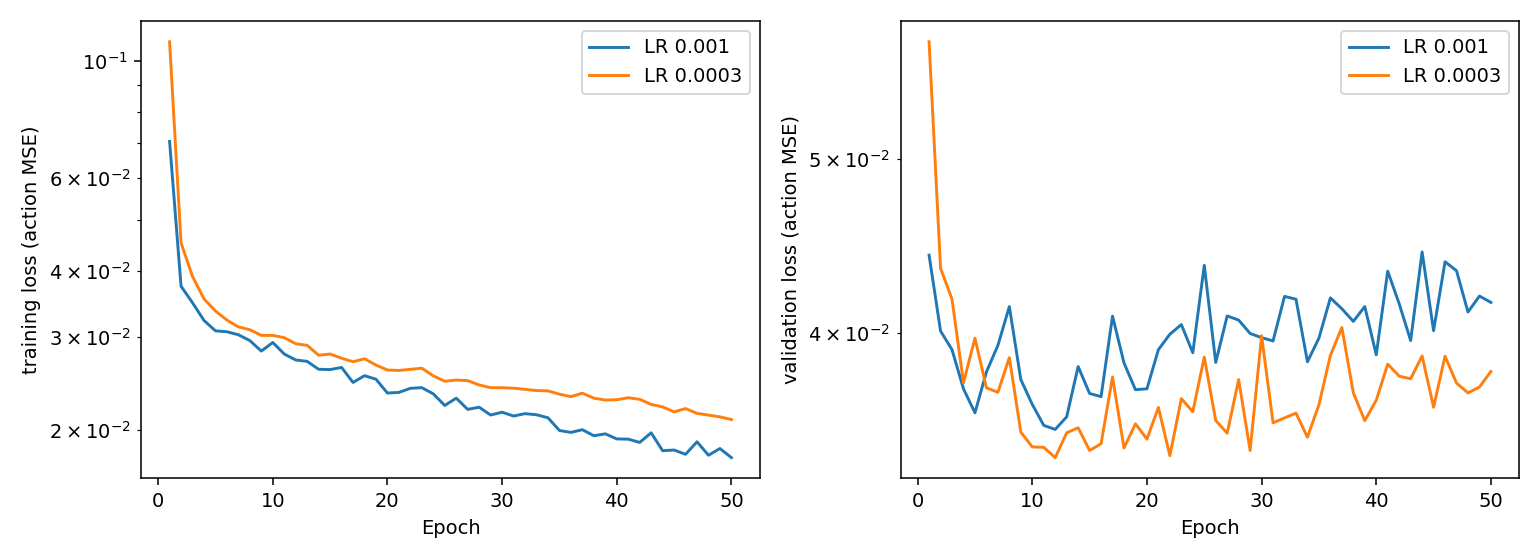

| variant | learning_rate | epochs | seed | selected_epoch | validation_mse | standard_stable_success_rate | shifted_stable_success_rate |
| --- | --- | --- | --- | --- | --- | --- | --- |
| lr_a | 0.001 | 50 | 17 | 12 | 0.03537582876584447 | 0.6 | 0.6 |
| lr_b | 0.0003 | 50 | 17 | 12 | 0.03412255911650028 | 1.0 | 1.0 |

### lr_a · learning rate 0.001

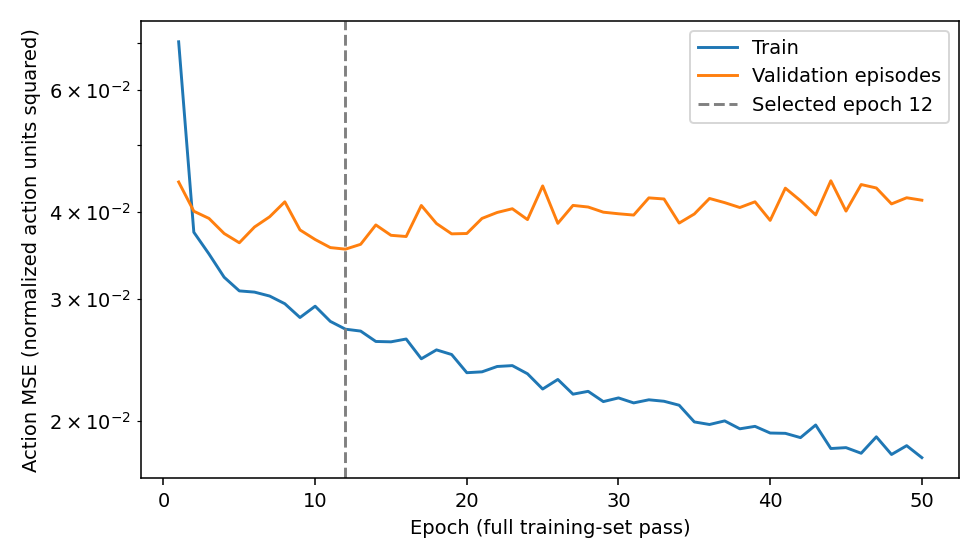

### lr_b · learning rate 0.0003

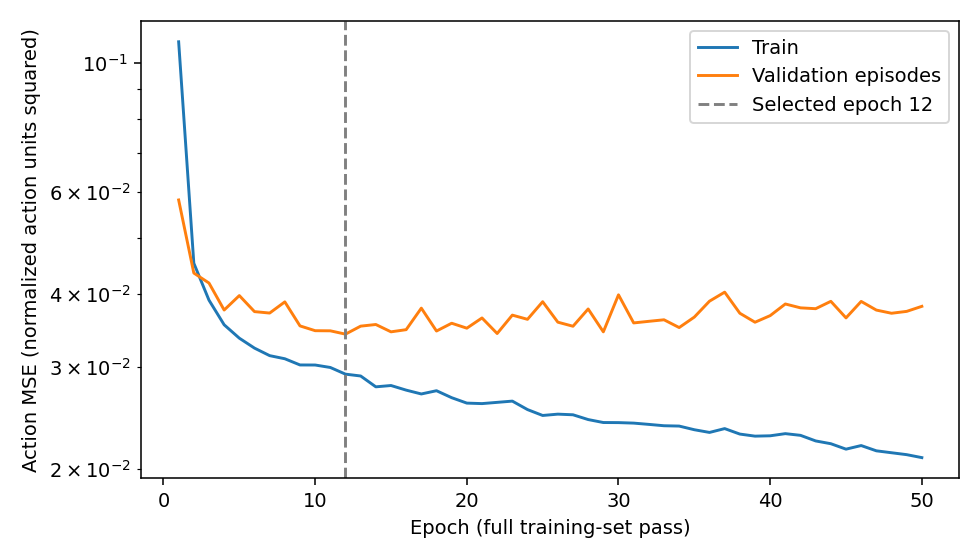

Both configurations, loss CSVs, checkpoints and 20 simulated episodes: /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/experiment_051841_40b7a2


In [4]:
display(Image(filename=str(EXPERIMENT / "learning_rate_curves.png")))
display(Markdown(markdown_table(experiment["comparison"])))
for variant, paths in experiment["variants"].items():
    display(Markdown("### " + variant + " · learning rate " + str(paths["learning_rate"])))
    display(Image(filename=str(EXPERIMENT / paths["training"] / "training_curve.png")))
print("Both configurations, loss CSVs, checkpoints and 20 simulated episodes:", EXPERIMENT)


## Expected Outputs
Two 50-epoch loss histories, two selected checkpoints, the initial-weight equality check, and the same 10 test conditions for each checkpoint. A completed run need not have a high success rate.

## Questions for Students
**Q2. How does behavior cloning learn from demonstrations?** Identify input, target, loss and parameter update.

**Q3. Does a lower training loss always result in better manipulation performance?** Compare both curves and actual success counts. Explain what five cases per condition cannot establish. You can revise this answer after Notebook 03.


In [2]:
Q2 = 'Behavior cloning is supervised learning of a policy pi_theta(o) that maps the current 16-value observation to the seven recorded expert action labels. The fixed deterministic MLP has three 256-unit hidden layers. It minimizes mean squared action error, averaged over examples and action coordinates; gradient-based updates change the network weights. An epoch traverses the training examples. Observation normalization uses training data only. Validation loss is measured without fitting validation labels and selects the saved checkpoint; both variants selected epoch 12 out of 50. The test episodes never update weights or select the primary model. The mandatory experiment changes only learning rate (0.001 vs 0.0003), keeping seed 17, batch size 256, data, episode split, initialization, network, normalization, training device and evaluation cases fixed. All four control checks passed. lr_a was declared primary before testing.'
Q3 = 'No. In this actual CPU run, epoch-50 training MSE is 0.01771696 for lr_a and 0.02091872 for lr_b, so lr_a fits training examples more closely. Their best validation MSE values are 0.03537583 and 0.03412256, both at epoch 12. Using those validation-selected checkpoints, lr_a achieves stable released placement in 3/5 standard and 3/5 shifted cases, while lr_b achieves 5/5 and 5/5. Environment-success counts happen to match stable-placement counts here, but the definitions differ. The evaluated weights are epoch-12 checkpoints, not the epoch-50 weights: this comparison warns against ranking policies by final training loss; it is not a causal test of loss at fixed weights. During closed-loop execution, each action changes subsequent observations, so errors can move the policy into states less well represented in demonstrations. Five cases per condition are coarse (one case equals 20 percentage points), and this one training seed cannot establish a generally superior learning rate. No unsuccessful cases were discarded or rerun to improve scores.'
answer_path = RUN / "discussion_answers.json"
answers = read_json(answer_path) if answer_path.exists() else {}
answers.update(q2=Q2, q3=Q3)
write_json(answer_path, answers)

display(Markdown("**Q2 — Instructor solution**\n\n" + Q2))
display(Markdown("**Q3 — Instructor solution**\n\n" + Q3))

**Q2 — Instructor solution**

Behavior cloning is supervised learning of a policy pi_theta(o) that maps the current 16-value observation to the seven recorded expert action labels. The fixed deterministic MLP has three 256-unit hidden layers. It minimizes mean squared action error, averaged over examples and action coordinates; gradient-based updates change the network weights. An epoch traverses the training examples. Observation normalization uses training data only. Validation loss is measured without fitting validation labels and selects the saved checkpoint; both variants selected epoch 12 out of 50. The test episodes never update weights or select the primary model. The mandatory experiment changes only learning rate (0.001 vs 0.0003), keeping seed 17, batch size 256, data, episode split, initialization, network, normalization, training device and evaluation cases fixed. All four control checks passed. lr_a was declared primary before testing.

**Q3 — Instructor solution**

No. In this actual CPU run, epoch-50 training MSE is 0.01771696 for lr_a and 0.02091872 for lr_b, so lr_a fits training examples more closely. Their best validation MSE values are 0.03537583 and 0.03412256, both at epoch 12. Using those validation-selected checkpoints, lr_a achieves stable released placement in 3/5 standard and 3/5 shifted cases, while lr_b achieves 5/5 and 5/5. Environment-success counts happen to match stable-placement counts here, but the definitions differ. The evaluated weights are epoch-12 checkpoints, not the epoch-50 weights: this comparison warns against ranking policies by final training loss; it is not a causal test of loss at fixed weights. During closed-loop execution, each action changes subsequent observations, so errors can move the policy into states less well represented in demonstrations. Five cases per condition are coarse (one case equals 20 percentage points), and this one training seed cannot establish a generally superior learning rate. No unsuccessful cases were discarded or rerun to improve scores.

## Completion Checklist
- [x] Both configurations completed with only learning rate changed.
- [x] I located both checkpoints, loss CSVs, selected epochs and configurations.
- [x] I compared convergence and test performance without changing seeds.
- [x] I saved Q2 and Q3. Continue to Notebook 03 to inspect the same evaluation evidence.
